In [1]:
python --version

NameError: name 'python' is not defined

In [2]:
!python --version


Python 3.12.10


In [3]:
print("Hello world")

Hello world


In [6]:

import pandas as pd

# Creating a small weather dataset
data = {
    "Temperature": [32, 25, 30, 24, 35],
    "Humidity": [75, 95, 80, 90, 60],
    "WindSpeed": [12, 20, 10, 18, 8],
    "Rain": ["No", "Yes", "No", "Yes", "No"]
}

# Convert data into DataFrame
df = pd.DataFrame(data)

# Display dataset
df


,Temperature,Humidity,WindSpeed,Rain
0,32,75,12,No
1,25,95,20,Yes
2,30,80,10,No
3,24,90,18,Yes
4,35,60,8,No


In [5]:
%pip install pandas numpy

  Using cached tzdata-2026.6-py2.py3-none-any.whl.metadata (1.4 kB)
   ---------------------------------------- 0.0/10.8 MB ? eta -:--:--
    --------------------------------------- 0.3/10.8 MB ? eta -:--:--
   --- ------------------------------------ 1.0/10.8 MB 3.4 MB/s eta 0:00:03
   ----- ---------------------------------- 1.6/10.8 MB 3.0 MB/s eta 0:00:04
   ------- -------------------------------- 2.1/10.8 MB 2.9 MB/s eta 0:00:03
   -------- ------------------------------- 2.4/10.8 MB 2.7 MB/s eta 0:00:04
   --------- ------------------------------ 2.6/10.8 MB 2.4 MB/s eta 0:00:04
   --------- ------------------------------ 2.6/10.8 MB 2.4 MB/s eta 0:00:04
   ---------- ----------------------------- 2.9/10.8 MB 2.0 MB/s eta 0:00:04
   ---------- ----------------------------- 2.9/10.8 MB 2.0 MB/s eta 0:00:04
   ----------- ---------------------------- 3.1/10.8 MB 1.7 MB/s eta 0:00:05
   ----------- ---------------------------- 3.1/10.8 MB 1.7 MB/s eta 0:00:05
   ------------ ------


[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
df.shape

(5, 4)

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Temperature  5 non-null      int64
 1   Humidity     5 non-null      int64
 2   WindSpeed    5 non-null      int64
 3   Rain         5 non-null      str  
dtypes: int64(3), str(1)
memory usage: 292.0 bytes


In [9]:
df.head()

,Temperature,Humidity,WindSpeed,Rain
0,32,75,12,No
1,25,95,20,Yes
2,30,80,10,No
3,24,90,18,Yes
4,35,60,8,No


In [10]:
df.columns

Index(['Temperature', 'Humidity', 'WindSpeed', 'Rain'], dtype='str')

In [11]:
df.describe

<bound method DataFrame.describe of    Temperature  Humidity  WindSpeed Rain
0           32        75         12   No
1           25        95         20  Yes
2           30        80         10   No
3           24        90         18  Yes
4           35        60          8   No>

In [12]:
df.isnull().sum()

Temperature    0
Humidity       0
WindSpeed      0
Rain           0
dtype: int64

EDA (Exploratory Data Analysis)-এর Algorithm
Algorithm: Explore and Analyze Weather Dataset
1. Start
2. Import necessary Python libraries (Pandas and NumPy).
3. Create or load the Weather Dataset.
4. Convert the dataset into a Pandas DataFrame.
5. Display the dataset.
6. Find the number of rows and columns using df.shape.
7. Display column names using df.columns.
8. Check dataset information using df.info().
9. Display the first five records using df.head().
10. Generate statistical summary using df.describe().
11. Identify missing values using df.isnull().sum().
12. Analyze the dataset to understand weather patterns.
13. Stop.

Linear Regression Implementation — Steps

In [14]:
X= df[['Humidity','WindSpeed']]
y=df['Temperature']

print(X.head())
print(y.head())

   Humidity  WindSpeed
0        75         12
1        95         20
2        80         10
3        90         18
4        60          8
0    32
1    25
2    30
3    24
4    35
Name: Temperature, dtype: int64


In [15]:
import pandas as pd
import json
from urllib.request import urlopen
from urllib.parse import urlencode

In [16]:
cities = {
    "Dhaka": (23.8103, 90.4125),
    "Chattogram": (22.3569, 91.7832),
    "Rajshahi": (24.3745, 88.6042),
    "Khulna": (22.8456, 89.5403),
    "Sylhet": (24.8949, 91.8687),
    "Barishal": (22.7010, 90.3535),
    "Rangpur": (25.7439, 89.2752),
    "Mymensingh": (24.7471, 90.4203)
}

In [18]:
import time

# All city coordinates
latitudes = ",".join(
    str(coords[0]) for coords in cities.values()
)

longitudes = ",".join(
    str(coords[1]) for coords in cities.values()
)

url = "https://archive-api.open-meteo.com/v1/archive"

params = {
    "latitude": latitudes,
    "longitude": longitudes,
    "start_date": "2020-01-01",
    "end_date": "2025-12-31",
    "hourly": (
        "temperature_2m,"
        "relative_humidity_2m,"
        "precipitation,"
        "rain,"
        "pressure_msl,"
        "wind_speed_10m,"
        "cloud_cover"
    ),
    "timezone": "Asia/Dhaka"
}

api_url = url + "?" + urlencode(params)

# One API request for all cities
with urlopen(api_url, timeout=120) as response:
    weather_data = json.loads(response.read())

all_data = []

# Convert each city's response into DataFrame
for city, city_data in zip(cities.keys(), weather_data):

    city_df = pd.DataFrame(city_data["hourly"])

    city_df["City"] = city

    all_data.append(city_df)

# Combine all cities
weather_df = pd.concat(all_data, ignore_index=True)

# Save CSV
weather_df.to_csv(
    "bangladesh_historical_weather.csv",
    index=False
)

print("All cities data collected!")
print("Dataset Shape:", weather_df.shape)

All cities data collected!
Dataset Shape: (420864, 9)


Data verification

In [19]:
print("Dataset Shape:", weather_df.shape)

print("\nFirst 5 Rows:")
display(weather_df.head())

print("\nCity-wise Data Count:")
print(weather_df["City"].value_counts())

print("\nMissing Values:")
print(weather_df.isnull().sum())

Dataset Shape: (420864, 9)

First 5 Rows:


,time,temperature_2m,relative_humidity_2m,precipitation,rain,pressure_msl,wind_speed_10m,cloud_cover,City
0,2020-01-01T00:00,18.3,74,0.0,0.0,1017.6,3.5,1,Dhaka
1,2020-01-01T01:00,16.5,81,0.0,0.0,1017.2,6.0,0,Dhaka
2,2020-01-01T02:00,14.6,89,0.0,0.0,1017.2,8.4,0,Dhaka
3,2020-01-01T03:00,14.5,90,0.0,0.0,1017.2,6.3,0,Dhaka
4,2020-01-01T04:00,14.1,90,0.0,0.0,1017.2,8.2,0,Dhaka



City-wise Data Count:
City
Dhaka         52608
Chattogram    52608
Rajshahi      52608
Khulna        52608
Sylhet        52608
Barishal      52608
Rangpur       52608
Mymensingh    52608
Name: count, dtype: int64

Missing Values:
time                    0
temperature_2m          0
relative_humidity_2m    0
precipitation           0
rain                    0
pressure_msl            0
wind_speed_10m          0
cloud_cover             0
City                    0
dtype: int64


Data Preprocessing

Data cleaning

In [20]:
# 1. Check duplicate rows
print("Duplicate Rows:", weather_df.duplicated().sum())

# 2. Check missing values
print("\nMissing Values:")
print(weather_df.isnull().sum())

# 3. Check data types
print("\nData Types:")
print(weather_df.dtypes)

# 4. Convert time into datetime
weather_df["time"] = pd.to_datetime(weather_df["time"])

# 5. Sort data by city and time
weather_df = weather_df.sort_values(
    ["City", "time"]
)

print("\nData Cleaning Check Completed!")

Duplicate Rows: 0

Missing Values:
time                    0
temperature_2m          0
relative_humidity_2m    0
precipitation           0
rain                    0
pressure_msl            0
wind_speed_10m          0
cloud_cover             0
City                    0
dtype: int64

Data Types:
time                        str
temperature_2m          float64
relative_humidity_2m      int64
precipitation           float64
rain                    float64
pressure_msl            float64
wind_speed_10m          float64
cloud_cover               int64
City                        str
dtype: object

Data Cleaning Check Completed!


Feature Engineering
সহজ ভাষায়, existing data থেকে নতুন useful information বা feature তৈরি করাকে Feature Engineering বলে।

In [21]:
# Extract time-based features

weather_df["time"] = pd.to_datetime(weather_df["time"])

weather_df["Hour"] = weather_df["time"].dt.hour

weather_df["Month"] = weather_df["time"].dt.month

weather_df["Day"] = weather_df["time"].dt.day

weather_df["DayOfWeek"] = weather_df["time"].dt.dayofweek

# Check new features
print(weather_df[
    ["time", "Hour", "Month", "Day", "DayOfWeek"]
].head())

                      time  Hour  Month  Day  DayOfWeek
263040 2020-01-01 00:00:00     0      1    1          2
263041 2020-01-01 01:00:00     1      1    1          2
263042 2020-01-01 02:00:00     2      1    1          2
263043 2020-01-01 03:00:00     3      1    1          2
263044 2020-01-01 04:00:00     4      1    1          2


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_29204\2034072656.py:11: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  weather_df["DayOfWeek"] = weather_df["time"].dt.dayofweek


In [23]:
#X,Y

# Input Features
X = weather_df[
    [
        "temperature_2m",
        "relative_humidity_2m",
        "wind_speed_10m",
        "pressure_msl",
        "cloud_cover",
        "Hour",
        "Month",
        "City"
    ]
]

# Convert City into numerical features
X = pd.get_dummies(X, columns=["City"], dtype=int)

# Target Variable
weather_df["Next_Hour_Temp"] = (
    weather_df.groupby("City")["temperature_2m"].shift(-1)
)
valid_rows = weather_df["Next_Hour_Temp"].notna()
X = X.loc[valid_rows]
y = weather_df.loc[valid_rows, "Next_Hour_Temp"]

print("X Shape:", X.shape)
print("y Shape:", y.shape)

display(X.head())
display(y.head())

X Shape: (420856, 15)
y Shape: (420856,)


,temperature_2m,relative_humidity_2m,wind_speed_10m,pressure_msl,cloud_cover,Hour,Month,City_Barishal,City_Chattogram,City_Dhaka,City_Khulna,City_Mymensingh,City_Rajshahi,City_Rangpur,City_Sylhet
263040,15.3,92,7.6,1017.6,5,0,1,1,0,0,0,0,0,0,0
263041,15.1,93,7.4,1017.3,8,1,1,1,0,0,0,0,0,0,0
263042,14.9,94,6.6,1017.2,6,2,1,1,0,0,0,0,0,0,0
263043,15.3,93,6.1,1017.0,6,3,1,1,0,0,0,0,0,0,0
263044,15.2,92,5.9,1017.0,15,4,1,1,0,0,0,0,0,0,0


263040    15.1
263041    14.9
263042    15.3
263043    15.2
263044    14.9
Name: Next_Hour_Temp, dtype: float64

Split the Data set

#Training Data[80%]
#testing data[20%]
# Sort data by time
weather_df = weather_df.sort_values("time")

# Find 80% time boundary
split_index = int(len(weather_df) * 0.8)

# Split X and y
X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.loc[X_train.index]
y_test = y.loc[X_test.index]

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)


In [26]:
# Sort data by time
weather_df = weather_df.sort_values("time")

# Find 80% time boundary
split_index = int(len(weather_df) * 0.8)

# Split X and y
X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.loc[X_train.index]
y_test = y.loc[X_test.index]

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (336691, 15)
Testing Data: (84165, 15)


In [28]:
# Sort historical data city-wise and time-wise
weather_df = weather_df.sort_values(["City", "time"])

# Find 80% time boundary separately for each city
city_cutoff = weather_df.groupby("City")["time"].transform(
    lambda x: x.quantile(0.8)
)

# Create training and testing indexes
train_index = weather_df.index[weather_df["time"] <= city_cutoff].intersection(X.index)
test_index = weather_df.index[weather_df["time"] > city_cutoff].intersection(X.index)

# Split input features
X_train = X.loc[train_index]
X_test = X.loc[test_index]

# Split target
y_train = y.loc[train_index]
y_test = y.loc[test_index]

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("Total Data:", len(X_train) + len(X_test))

Training Data: (336688, 15)
Testing Data: (84168, 15)
Total Data: 420856


Step 4: Linear Regression Model Training

In [29]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [30]:
# Create model
model = LinearRegression()

# Train model
model.fit(X_train, y_train)

print("Model Training Completed!")

Model Training Completed!


In [31]:
y_pred = model.predict(X_test)

print("Actual Temperature:")
print(y_test.head())

print("\nPredicted Temperature:")
print(y_pred[:5])

Actual Temperature:
305126    30.0
305127    29.4
305128    28.1
305129    26.8
305130    25.3
Name: Next_Hour_Temp, dtype: float64

Predicted Temperature:
[30.12590018 30.01001291 29.41415589 27.92425984 26.75570198]


In [32]:
from urllib.request import urlopen
from urllib.parse import urlencode
import json
import pandas as pd

# All city coordinates
latitudes = ",".join(str(c[0]) for c in cities.values())
longitudes = ",".join(str(c[1]) for c in cities.values())

url = "https://api.open-meteo.com/v1/forecast"

params = {
    "latitude": latitudes,
    "longitude": longitudes,
    "current": (
        "temperature_2m,"
        "relative_humidity_2m,"
        "wind_speed_10m,"
        "pressure_msl,"
        "cloud_cover"
    ),
    "timezone": "Asia/Dhaka"
}

api_url = url + "?" + urlencode(params)

with urlopen(api_url, timeout=60) as response:
    live_data = json.loads(response.read())

print("Live weather data collected!")

Live weather data collected!


In [33]:
live_rows = []

for city, data in zip(cities.keys(), live_data):

    current = data["current"]
    current_time = pd.to_datetime(current["time"])

    live_rows.append({
        "City": city,
        "temperature_2m": current["temperature_2m"],
        "relative_humidity_2m": current["relative_humidity_2m"],
        "wind_speed_10m": current["wind_speed_10m"],
        "pressure_msl": current["pressure_msl"],
        "cloud_cover": current["cloud_cover"],
        "Hour": current_time.hour,
        "Month": current_time.month
    })

live_df = pd.DataFrame(live_rows)

# Convert city into one-hot encoded columns
live_X = pd.get_dummies(
    live_df,
    columns=["City"],
    dtype=int
)

# Match the training feature columns
live_X = live_X.reindex(columns=X.columns, fill_value=0)

# Predict next-hour temperature
live_predictions = model.predict(live_X)

# Display results
results = pd.DataFrame({
    "City": live_df["City"],
    "Current Temperature": live_df["temperature_2m"],
    "Predicted Next Hour Temperature": live_predictions
})

display(results.round(2))

,City,Current Temperature,Predicted Next Hour Temperature
0,Dhaka,25.2,25.48
1,Chattogram,25.2,25.36
2,Rajshahi,24.1,24.49
3,Khulna,24.8,25.33
4,Sylhet,23.0,23.34
5,Barishal,25.5,25.79
6,Rangpur,23.4,23.69
7,Mymensingh,23.4,23.73


In [34]:
live_rows = []

for city, data in zip(cities.keys(), live_data):

    current = data["current"]
    current_time = pd.to_datetime(current["time"])

    live_rows.append({
        "City": city,
        "Current Time": current_time,
        "Prediction For": current_time + pd.Timedelta(hours=1),
        "temperature_2m": current["temperature_2m"],
        "relative_humidity_2m": current["relative_humidity_2m"],
        "wind_speed_10m": current["wind_speed_10m"],
        "pressure_msl": current["pressure_msl"],
        "cloud_cover": current["cloud_cover"],
        "Hour": current_time.hour,
        "Month": current_time.month
    })

live_df = pd.DataFrame(live_rows)

# Prepare input features
live_X = live_df[X.columns.intersection(live_df.columns)]

live_X = pd.get_dummies(
    live_df.drop(columns=["Current Time", "Prediction For"]),
    columns=["City"],
    dtype=int
)

live_X = live_X.reindex(columns=X.columns, fill_value=0)

# Predict
live_predictions = model.predict(live_X)

# Final results
results = pd.DataFrame({
    "City": live_df["City"],
    "Current Time": live_df["Current Time"],
    "Prediction For": live_df["Prediction For"],
    "Current Temp (°C)": live_df["temperature_2m"],
    "Predicted Temp (°C)": live_predictions
})

display(results.round(2))

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_29204\1816486964.py:46: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(results.round(2))


,City,Current Time,Prediction For,Current Temp (°C),Predicted Temp (°C)
0,Dhaka,2026-11-16 08:30:00,2026-11-16 09:30:00,25.2,25.48
1,Chattogram,2026-11-16 08:30:00,2026-11-16 09:30:00,25.2,25.36
2,Rajshahi,2026-11-16 08:30:00,2026-11-16 09:30:00,24.1,24.49
3,Khulna,2026-11-16 08:30:00,2026-11-16 09:30:00,24.8,25.33
4,Sylhet,2026-11-16 08:30:00,2026-11-16 09:30:00,23.0,23.34
5,Barishal,2026-11-16 08:30:00,2026-11-16 09:30:00,25.5,25.79
6,Rangpur,2026-11-16 08:30:00,2026-11-16 09:30:00,23.4,23.69
7,Mymensingh,2026-11-16 08:30:00,2026-11-16 09:30:00,23.4,23.73


1. MAE, MSE, RMSE ও R²

In [35]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = mse ** 0.5

r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("------------------------")
print("MAE:", round(mae, 3), "°C")
print("MSE:", round(mse, 3))
print("RMSE:", round(rmse, 3), "°C")
print("R2 Score:", round(r2, 4))

Model Evaluation Results
------------------------
MAE: 0.727 °C
MSE: 0.926
RMSE: 0.962 °C
R2 Score: 0.9631


In [36]:

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# 1. MAE
mae = mean_absolute_error(y_test, y_pred)

# 2. MSE
mse = mean_squared_error(y_test, y_pred)

# 3. RMSE
rmse = mse ** 0.5

# 4. R2 Score
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)


MAE: 0.7272824157900359
MSE: 0.926322459715847
RMSE: 0.9624564715953896
R2 Score: 0.9631209554752271


In [38]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = mse ** 0.5
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 0.7272824157900359
MSE: 0.926322459715847
RMSE: 0.9624564715953896
R2 Score: 0.9631209554752271


In [40]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)


ValueError: continuous is not supported

In [41]:
# Sort data by city and time
weather_df = weather_df.sort_values(["City", "time"])

# Find next hour rainfall
weather_df["Next_Hour_Rain"] = (
    weather_df.groupby("City")["rain"].shift(-1)
)

# Convert rainfall into binary target
weather_df["Rain_Target"] = (
    weather_df["Next_Hour_Rain"] > 0
).astype(int)

# Remove missing values
weather_df = weather_df.dropna(
    subset=["Next_Hour_Rain"]
)

# Count Rain and No Rain
print(weather_df["Rain_Target"].value_counts())

Rain_Target
0    317978
1    102878
Name: count, dtype: int64


In [42]:
weather_df = weather_df.sort_values(["City", "time"])

weather_df["Next_Hour_Rain"] = (
    weather_df.groupby("City")["rain"].shift(-1)
)

weather_df["Rain_Target"] = (
    weather_df["Next_Hour_Rain"] > 0
).astype(int)

weather_df = weather_df.dropna(
    subset=["Next_Hour_Rain"]
)

print(weather_df["Rain_Target"].value_counts())

Rain_Target
0    317970
1    102878
Name: count, dtype: int64


In [43]:
print(
    weather_df["Rain_Target"].value_counts(normalize=True) * 100
)

Rain_Target
0    75.554595
1    24.445405
Name: proportion, dtype: float64


In [44]:
# Input features
X_rain = weather_df[
    [
        "temperature_2m",
        "relative_humidity_2m",
        "wind_speed_10m",
        "pressure_msl",
        "cloud_cover",
        "Hour",
        "Month",
        "City"
    ]
]

# Convert City into numerical columns
X_rain = pd.get_dummies(
    X_rain,
    columns=["City"],
    dtype=int
)

# Output target
y_rain = weather_df["Rain_Target"]

print("Features:", X_rain.shape)
print("Target:", y_rain.shape)

Features: (420848, 15)
Target: (420848,)


In [45]:
# Sort data by city and time
weather_df = weather_df.sort_values(["City", "time"])

# Find 80% time cutoff for each city
city_cutoff = weather_df.groupby("City")["time"].transform(
    lambda x: x.quantile(0.8)
)

# Split row indexes
train_index = weather_df.index[
    weather_df["time"] <= city_cutoff
]

test_index = weather_df.index[
    weather_df["time"] > city_cutoff
]

# Split features
X_train_rain = X_rain.loc[train_index]
X_test_rain = X_rain.loc[test_index]

# Split target
y_train_rain = y_rain.loc[train_index]
y_test_rain = y_rain.loc[test_index]

print("Training:", X_train_rain.shape)
print("Testing:", X_test_rain.shape)

Training: (336680, 15)
Testing: (84168, 15)


In [46]:
from sklearn.preprocessing import StandardScaler

# Create scaler
scaler = StandardScaler()

# Learn from training data and transform
X_train_scaled = scaler.fit_transform(X_train_rain)

# Transform testing data
X_test_scaled = scaler.transform(X_test_rain)

print("Training:", X_train_scaled.shape)
print("Testing:", X_test_scaled.shape)

Training: (336680, 15)
Testing: (84168, 15)


In [47]:
from sklearn.linear_model import LogisticRegression

# Create model
rain_model = LogisticRegression(max_iter=1000)

# Train model
rain_model.fit(X_train_scaled, y_train_rain)

print("Rain Prediction Model Training Complete!")

Rain Prediction Model Training Complete!


# Predict using test data
y_pred_rain = rain_model.predict(X_test_scaled)

# Show actual and predicted values
print("Actual values:")
print(y_test_rain.head(10).values)

print("\nPredicted values:")
print(y_pred_rain[:10])

In [48]:
# Predict using test data
y_pred_rain = rain_model.predict(X_test_scaled)

# Show actual and predicted values
print("Actual values:")
print(y_test_rain.head(10).values)

print("\nPredicted values:")
print(y_pred_rain[:10])

Actual values:
[0 1 1 1 0 0 0 0 0 0]

Predicted values:
[0 0 0 0 0 0 0 0 0 0]


In [49]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test_rain, y_pred_rain)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[61095  6006]
 [ 7046 10021]]


In [50]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

accuracy = accuracy_score(y_test_rain, y_pred_rain)
precision = precision_score(y_test_rain, y_pred_rain)
recall = recall_score(y_test_rain, y_pred_rain)
f1 = f1_score(y_test_rain, y_pred_rain)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

Accuracy: 0.8449291892405665
Precision: 0.6252573781743308
Recall: 0.5871565008495928
F1 Score: 0.6056082673596422


In [51]:
cluster_data = weather_df[
    [
        "temperature_2m",
        "relative_humidity_2m",
        "wind_speed_10m",
        "pressure_msl",
        "cloud_cover"
    ]
].copy()

print(cluster_data.head())
print("Shape:", cluster_data.shape)

        temperature_2m  relative_humidity_2m  wind_speed_10m  pressure_msl  \
263040            15.3                    92             7.6        1017.6   
263041            15.1                    93             7.4        1017.3   
263042            14.9                    94             6.6        1017.2   
263043            15.3                    93             6.1        1017.0   
263044            15.2                    92             5.9        1017.0   

        cloud_cover  
263040            5  
263041            8  
263042            6  
263043            6  
263044           15  
Shape: (420848, 5)


In [52]:
from sklearn.preprocessing import StandardScaler

cluster_scaler = StandardScaler()

cluster_scaled = cluster_scaler.fit_transform(cluster_data)

print("Original shape:", cluster_data.shape)
print("Scaled shape:", cluster_scaled.shape)

Original shape: (420848, 5)
Scaled shape: (420848, 5)


In [53]:
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

kmeans.fit(cluster_scaled)

print("Clustering Complete!")

Clustering Complete!


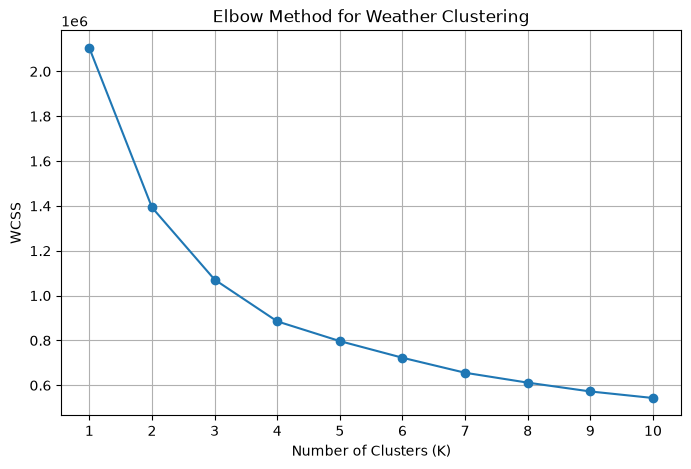

In [54]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

wcss = []

for k in range(1, 11):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(cluster_scaled)

    wcss.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o')

plt.title("Elbow Method for Weather Clustering")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

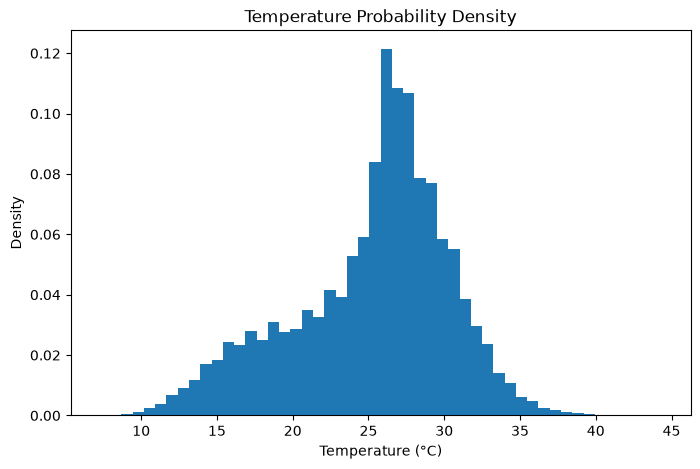

In [55]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(
    weather_df["temperature_2m"],
    bins=50,
    density=True
)

plt.title("Temperature Probability Density")
plt.xlabel("Temperature (°C)")
plt.ylabel("Density")

plt.show()

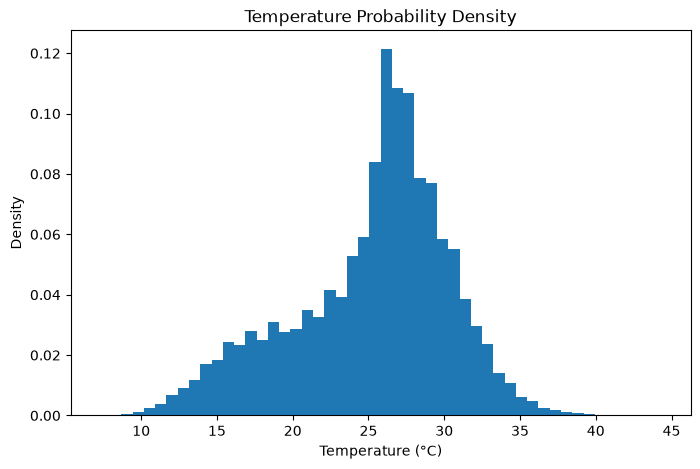

In [56]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(
    weather_df["temperature_2m"],
    bins=50,
    density=True
)

plt.title("Temperature Probability Density")
plt.xlabel("Temperature (°C)")
plt.ylabel("Density")

plt.show()

In [58]:
weather_df = weather_df.sort_values(["City", "time"]).copy()

weather_df["Weather_State"] = weather_df["rain"].gt(0).map({
    True: "Rain",
    False: "No Rain"
})

weather_df["Next_State"] = (
    weather_df.groupby("City")["Weather_State"].shift(-1)
)

transition_counts = pd.crosstab(
    weather_df["Weather_State"],
    weather_df["Next_State"]
)

print(transition_counts)

Next_State     No Rain   Rain
Weather_State                
No Rain         297337  20625
Rain             20625  82253


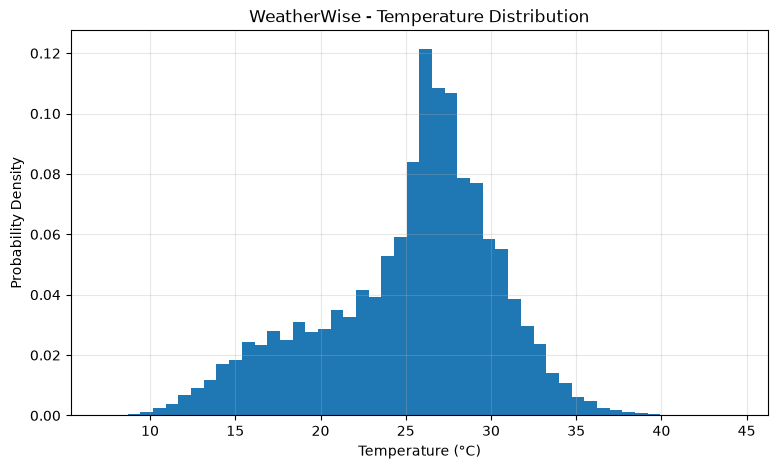

In [59]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.hist(
    weather_df["temperature_2m"].dropna(),
    bins=50,
    density=True
)

plt.title("WeatherWise - Temperature Distribution")
plt.xlabel("Temperature (°C)")
plt.ylabel("Probability Density")

plt.grid(alpha=0.3)
plt.show()

In [60]:
weather_df = weather_df.sort_values(["City", "time"])

weather_df["Weather_State"] = (
    weather_df["rain"] > 0
).astype(int)

weather_df["Next_State"] = (
    weather_df.groupby("City")["Weather_State"].shift(-1)
)

transition_counts = pd.crosstab(
    weather_df["Weather_State"],
    weather_df["Next_State"]
)

transition_matrix = transition_counts.div(
    transition_counts.sum(axis=1),
    axis=0
)

print("Markov Transition Matrix:")
print(transition_matrix)

Markov Transition Matrix:
Next_State          0.0       1.0
Weather_State                    
0              0.935134  0.064866
1              0.200480  0.799520


In [61]:
from sklearn.metrics import accuracy_score

train_pred = rain_model.predict(X_train_scaled)
test_pred = rain_model.predict(X_test_scaled)

train_accuracy = accuracy_score(
    y_train_rain,
    train_pred
)

test_accuracy = accuracy_score(
    y_test_rain,
    test_pred
)

print("Training Accuracy:", train_accuracy)
print("Testing Accuracy:", test_accuracy)

print(
    "Accuracy Difference:",
    train_accuracy - test_accuracy
)

Training Accuracy: 0.8105292859688725
Testing Accuracy: 0.8449291892405665
Accuracy Difference: -0.034399903271693955


In [62]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

lda = LinearDiscriminantAnalysis(
    n_components=1
)

X_train_lda = lda.fit_transform(
    X_train_scaled,
    y_train_rain
)

X_test_lda = lda.transform(
    X_test_scaled
)

print("Original Features:", X_train_scaled.shape[1])
print("LDA Features:", X_train_lda.shape[1])

Original Features: 15
LDA Features: 1


In [63]:
from sklearn.linear_model import LogisticRegression

lda_model = LogisticRegression(max_iter=1000)

lda_model.fit(X_train_lda, y_train_rain)

lda_predictions = lda_model.predict(X_test_lda)

lda_accuracy = accuracy_score(
    y_test_rain,
    lda_predictions
)

print("LDA Model Accuracy:", lda_accuracy)

LDA Model Accuracy: 0.8481014162151886
